# GET STATS FOR ENCODING SCHEMES (Methods §3.5)

The same measures computed over the whole corpus and then within each cluster: interaction properties
per agent (turns and characters), the sequence indicators of Ritschard (2023), normalised label
frequencies and the most frequent n-grams.

* **Input:** `logs_w_cluster/<coding scheme>.csv`
* **Output:** tables and figures in `results/`
* **Check:** the three clusters of each scheme differ in length, diversity and label mix


## DEPENDENCIES

In [1]:
from pathlib import Path
import os
import math
import warnings

import numpy as np
import pandas as pd
import pm4py

warnings.filterwarnings('ignore', category=UserWarning)

## SEQUENCE ANALYSIS STATISTICS

In [2]:
def get_entropy(sequence):
    "Computes the normalised [Shannon entropy](https://en.wikipedia.org/wiki/Entropy_(information_theory)) of a given sequence. Note that this measure is insensitive to transition frequency or event order, so should be used in conjunction with other measures."

    alphabet = set(sequence)

    entropy = 0
    for state in alphabet:
        proportion_occurances = sequence.count(state) / len(sequence)
        entropy += proportion_occurances * math.log(proportion_occurances)

    maximal_occurances = 1 / len(alphabet)
    alphabet_entropy = sum([maximal_occurances * math.log(maximal_occurances) for x in alphabet])

    if alphabet_entropy == 0:
        return 0

    return -entropy / -alphabet_entropy


# src: https://github.com/pysan-dev/pysan/blob/master/14_transitions.ipynb
def get_ntransitions(sequence):
    "Extracts a list of transitions from a sequence, returning the number of transitions."

    transitions = []
    for position in range(len(sequence) - 1):
        if sequence[position] != sequence[position + 1]:
            transitions.append([sequence[position], sequence[position + 1]])

    return len(transitions)

def get_complexity(sequence):
    "Computes the complexity of a given sequence, based on TraMineR's [seqici](http://traminer.unige.ch/doc/seqici.html) method."

    alphabet = set(sequence)

    pre_log = 1 / len(alphabet)
    hmax = -math.log(pre_log)

    if hmax == 0:
        return 0 # all identical elements, no complexity

    hs = get_entropy(sequence)
    qs = get_ntransitions(sequence)

    qmax = len(sequence) - 1


    norm_transitions = qs / qmax
    norm_entropy = hs / hmax

    complexity = math.sqrt(norm_transitions * norm_entropy)

    return complexity

def get_seq_stats(df, activity_key, case_id_key, timestamp_key,
                  round=False,
                  digits=3):
  # Store the results
  results = {}
  # Concatenate the activity with the role of the speaker
  df['activity'] = df['role'].str[:1] + '_' + df[activity_key]
  # Transform into an event log
  ccel = pm4py.format_dataframe(df.copy(),
                                case_id=case_id_key,
                                activity_key='activity',
                                timestamp_key=timestamp_key,
                                )
  # To store states and activities
  n_states = []
  n_spells = []
  seq_complexity = []
  seq_entropy = []
  # Get the variants [dictionary variant: tuple, freq: int]
  variants = pm4py.stats.get_variants(ccel)

  for variant in variants:

    # Number of distinct states/activities (§3.5: states)
    states = [len(set(variant))]

    # Multiply by the number of times the variant appears
    n_states += states * variants[variant]

    # Number of label changes (§3.5: spells)
    spells = [get_ntransitions(list(variant))]
    # Multiply by the number of times the variant appears
    n_spells += spells * variants[variant]

    complexity = [get_complexity(variant)]

    seq_complexity += complexity * variants[variant]

    entropy = [get_entropy(variant)]

    seq_entropy += entropy * variants[variant]

  # Mean of states
  results['mean_n_states'] = np.mean(n_states)
  # Median of states
  results['median_n_states'] = np.median(n_states)
  # Mean of spells
  results['mean_n_spells'] = np.mean(n_spells)
  # Median of spells
  results['median_n_spells'] = np.median(n_spells)

  results['mean_complexity'] = np.mean(seq_complexity)
  results['median_complexity'] = np.median(seq_complexity)

  results['mean_entropy'] = np.mean(seq_entropy)
  results['median_entropy'] = np.median(seq_entropy)
  if round:
    for e in results:
        results[e] = np.round(results[e], digits)
  return results

## PROCESS MINING STATISTICS

In [3]:
def get_pm_log_stats(df, activity_key, case_id_key, timestamp_key):
  # Store the results
  results = {}
  # Concatenate the activity with the role of the speaker
  df['activity'] = df['role'].str[:1] + '_' + df[activity_key]
  # Transform into an event log
  ccel = pm4py.format_dataframe(df.copy(),
                                case_id=case_id_key,
                                activity_key='activity',
                                timestamp_key=timestamp_key)
  # Get the variants
  variants = pm4py.stats.get_variants(ccel)

  # Number of variants
  results['n_of_variants'] = len(variants)
  # Start activities
  results['start_activities'] = pm4py.stats.get_start_activities(ccel)
  # End activities
  results['end_activities'] = pm4py.stats.get_end_activities(ccel)

  return results

In [4]:
def add_unused_tags(dict, list):

    for e in list:
        if e not in dict.keys():
            if '(' in e:
                e = e.split('(')
                e = e[0].strip(' ')
                if e not in dict.keys():
                    dict[e] = 0
            else:
                dict[e] = 0
    return dict

def get_frequency_of_activities(df, tags,
                                activity_key,
                                case_id_key,
                                timestamp_key,
                                normalize=False):

    frequency = {}
    if activity_key == 'label':
        labels = []
        for e in tags:
            labels += tags[e]
    else:
        labels = list(tags.keys())

    ccel = pm4py.format_dataframe(df.copy(),
                                case_id=case_id_key,
                                activity_key=activity_key,
                                timestamp_key=timestamp_key)

    # Get frequency of model utterances
    just_model = ccel[ccel['role'] == 'model']
    # Get frequency for labels
    model_labels = pm4py.stats.get_event_attribute_values(just_model, attribute='concept:name')
    model_labels = add_unused_tags(model_labels, labels)
    frequency['model_labels'] = model_labels

    # Get frequency of user utterances
    just_user = ccel[ccel['role'] == 'user']
    # Get frequency for labels
    user_labels = pm4py.stats.get_event_attribute_values(just_user, attribute='concept:name')
    user_labels = add_unused_tags(user_labels, labels)
    frequency['user_labels'] = user_labels

    if normalize:
        amount = len(ccel['concept:name'])
        for dictionary in frequency:
            aux = frequency[dictionary]
            for value in aux:
                aux[value] = round(aux[value]/amount,5)

    return frequency

# CLUSTER DESCRIPTIVE STATISTICS

In [5]:
def count_turns(log):
    counts = {}

    count_df = log.groupby(['cluster', 'case_id', 'role']).agg(
        role_count=('role', 'count')
        ).reset_index()

    for cluster in sorted(count_df['cluster'].unique()):
        counts[cluster] = {}
        temp = count_df[count_df['cluster']== cluster]
        for role in sorted(temp['role'].unique()):
            list_count = temp[temp['role'] == role]['role_count']
            counts[cluster][role] = list(list_count)

    return counts

def get_distribution_for_clusters(log):
    counts = {}
    # Get the amount of conversations in each cluster
    for cluster in log['cluster'].unique():
        temp = log[log['cluster'] == cluster]
        counts[cluster] = len(temp['case_id'].unique())
    return counts


def sum_sentence_length(log):

    counts = {}

    count_df = log.groupby(['cluster', 'case_id', 'role']).agg(
        sentence_length_sum=('sentence_en', lambda x: x.str.len().sum())  # Sum of sentence lengths
    ).reset_index()

    # Populate the nested dictionary
    for cluster in sorted(count_df['cluster'].unique()):
        counts[cluster] = {}
        temp = count_df[count_df['cluster'] == cluster]
        for role in sorted(temp['role'].unique()):
            list_lengths = temp[temp['role'] == role]['sentence_length_sum']
            counts[cluster][role] = list(list_lengths)

    return counts

In [6]:
def coding_count_turns(log):
    counts = {}

    count_df = log.groupby(['case_id', 'role']).agg(
        role_count=('role', 'count')
    ).reset_index()

    for role in sorted(count_df['role'].unique()):
        list_count = count_df[count_df['role'] == role]['role_count']
        counts[role] = list(list_count)

    return counts

def coding_get_distribution_for_sample(log):
    return len(log['case_id'].unique())

def coding_sum_sentence_length(log):
    counts = {}

    count_df = log.groupby(['case_id', 'role']).agg(
        sentence_length_sum=('sentence_en', lambda x: x.str.len().sum())
    ).reset_index()

    for role in sorted(count_df['role'].unique()):
        list_lengths = count_df[count_df['role'] == role]['sentence_length_sum']
        counts[role] = list(list_lengths)

    return counts

## DEFINE ENVIRONMENTAL VARIABLES

In [7]:
# Dataset to work on: 'data' is the study data, 'data_example' the synthetic example.
DATA = Path('..') / os.environ.get('DATASET_FOLDER', 'data')

IN_FOLDER = 'logs_w_cluster'
CODING_SCHEMES = [
                 'lin_dialogue_acts',
                 'acosta_epistemic_stance',
                 'del_bosque_cma'
                ]
OUT_FOLDER = 'results'

# Names given to the clusters in the paper
PROFILE_NAMES = {
    'lin_dialogue_acts': {0: 'Extended-engagement', 1: 'Task-completion', 2: 'Front-loading'},
    'acosta_epistemic_stance': {0: 'Assignment-driven', 1: 'Gap-filling', 2: 'Sense-making'},
    'del_bosque_cma': {0: 'Tutored', 1: 'Passive', 2: 'Collaborative'},
}

## READ FILES

In [8]:
import json

# Relative path
path_conversations = DATA / IN_FOLDER
path_tables = DATA / OUT_FOLDER / 'tables'
path_figures = DATA / OUT_FOLDER / 'figures'
path_tables.mkdir(parents=True, exist_ok=True)
path_figures.mkdir(parents=True, exist_ok=True)

logs = {}
coding_schemes = {}
for code in CODING_SCHEMES:
    path_coding_scheme = Path('..') / "coding_schemes" / code

    # Read dataframe
    df = pd.read_csv(path_conversations / (code + '.csv'))

    logs[code] = df

    with open(path_coding_scheme / 'tags.json') as f:
        coding_scheme = json.load(f)
        coding_schemes[code] = coding_scheme

## ENCODING SCHEME STATS

In [9]:
print('Turns')
rows = []
for j, coding_scheme in enumerate(logs):
    total_count = coding_count_turns(logs[coding_scheme])
    stats = {}
    for k in total_count:
        stats[k + '_mean'] = np.mean(total_count[k])
        stats[k + '_median'] = np.median(total_count[k])

    print(coding_scheme, stats)
    rows.append({'coding_scheme': coding_scheme, 'measure': 'turns', **stats})


print('\nChars')

for j, coding_scheme in enumerate(logs):
    total_count = coding_sum_sentence_length(logs[coding_scheme])

    stats = {}
    for k in total_count:
        stats[k + '_mean'] = np.mean(total_count[k])
        stats[k + '_median'] = np.median(total_count[k])

    print(coding_scheme, stats)
    rows.append({'coding_scheme': coding_scheme, 'measure': 'characters', **stats})

pd.DataFrame(rows).round(3).to_csv(path_tables / 'aggregate_interaction_properties.csv', index=False)

Turns
lin_dialogue_acts {'model_mean': 16.38607594936709, 'model_median': 16.0, 'user_mean': 4.29559748427673, 'user_median': 4.0}
acosta_epistemic_stance {'model_mean': 15.215189873417721, 'model_median': 15.0, 'user_mean': 4.666666666666667, 'user_median': 5.0}
del_bosque_cma {'model_mean': 15.69620253164557, 'model_median': 15.0, 'user_mean': 4.320754716981132, 'user_median': 4.0}

Chars
lin_dialogue_acts {'model_mean': 2191.987341772152, 'model_median': 2123.0, 'user_mean': 633.9937106918239, 'user_median': 547.0}
acosta_epistemic_stance {'model_mean': 2193.6012658227846, 'model_median': 2120.5, 'user_mean': 633.6918238993711, 'user_median': 547.0}
del_bosque_cma {'model_mean': 2193.993670886076, 'model_median': 2123.0, 'user_mean': 634.4905660377359, 'user_median': 547.0}


## Sequence indicators, whole corpus

In [10]:
rows = []
for code in logs:
    res = get_seq_stats(logs[code].copy(), activity_key='ocel:activity', case_id_key='case_id',
                        timestamp_key='ocel:timestamp', round=True)
    print(code, res)
    rows.append({'coding_scheme': code, **res})

pd.DataFrame(rows).to_csv(path_tables / 'aggregate_sequence_indicators.csv', index=False)

lin_dialogue_acts {'mean_n_states': 7.377, 'median_n_states': 7.0, 'mean_n_spells': 19.579, 'median_n_spells': 19.0, 'mean_complexity': 0.695, 'median_complexity': 0.682, 'mean_entropy': 0.927, 'median_entropy': 0.928}
acosta_epistemic_stance {'mean_n_states': 6.195, 'median_n_states': 6.0, 'mean_n_spells': 18.786, 'median_n_spells': 18.0, 'mean_complexity': 0.713, 'median_complexity': 0.698, 'mean_entropy': 0.898, 'median_entropy': 0.902}
del_bosque_cma {'mean_n_states': 5.887, 'median_n_states': 6.0, 'mean_n_spells': 18.918, 'median_n_spells': 19.0, 'mean_complexity': 0.732, 'median_complexity': 0.725, 'mean_entropy': 0.929, 'median_entropy': 0.933}


/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),


## Normalised label frequencies

In [11]:
data = {}
normalize = True
for code in logs:
    df = logs[code]

    result = get_frequency_of_activities(df, coding_schemes[code],
                                           activity_key='ocel:activity',
                                           case_id_key='case_id',
                                           timestamp_key='ocel:timestamp',
                                           normalize=normalize
                                           )

    data[code] = result

rows = []
for code in data:
    for role in data[code]:
        for label, value in data[code][role].items():
            rows.append({'coding_scheme': code, 'role': role.replace('_labels', ''),
                         'activity': label, 'frequency': value})

frequencies = pd.DataFrame(rows)
frequencies.to_csv(path_tables / 'aggregate_activity_frequencies.csv', index=False)
frequencies.pivot_table(index=['coding_scheme', 'activity'], columns='role', values='frequency',
                        fill_value=0)

/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),


role                                                                  model   
coding_scheme           activity                                              
acosta_epistemic_stance K+                                          0.09981  \
                        K-                                          0.24412   
                        Other                                       0.30420   
                        Reply                                       0.04990   
                        Reply-knowledge                             0.06612   
del_bosque_cma          Acknowledge Backchannel                     0.20903   
                        Backchannel through Repetition              0.00000   
                        Exclamation                                 0.00347   
                        No CMA Detected                             0.00158   
                        Other                                       0.00000   
                        Student Backchannel                         0.00000   
                        Student Compound Contribution               0.00000   
                        Student Question                            0.00000   
                        Tutor Diagnosing Base                       0.03063   
                        Tutor Elicit Response                       0.22766   
                        Tutor Floor Initiating or Floor Mantaining  0.23492   
                        Tutor Question Response                     0.07578   
lin_dialogue_acts       Acknowledge                                 0.04065   
                        Answer                                      0.00092   
                        Correction                                  0.00153   
                        Directive                                   0.04768   
                        Hint                                        0.10758   
                        Lukewarm Feedback                           0.00489   
                        Negative Feedback                           0.00183   
                        Other                                       0.00031   
                        Positive Feedback                           0.15617   
                        Question                                    0.21852   
                        Request Confirmation                        0.01100   
                        Request Feedback                            0.00489   
                        Statement                                   0.19529   

role                                                                   user  
coding_scheme           activity                                             
acosta_epistemic_stance K+                                          0.11157  
                        K-                                          0.02289  
                        Other                                       0.00636  
                        Reply                                       0.05785  
                        Reply-knowledge                             0.03719  
del_bosque_cma          Acknowledge Backchannel                     0.00000  
                        Backchannel through Repetition              0.00000  
                        Exclamation                                 0.00221  
                        No CMA Detected                             0.00000  
                        Other                                       0.00126  
                        Student Backchannel                         0.05147  
                        Student Compound Contribution               0.13704  
                        Student Question                            0.02494  
                        Tutor Diagnosing Base                       0.00000  
                        Tutor Elicit Response                       0.00000  
                        Tutor Floor Initiating or Floor Mantaining  0.00000  
                        Tutor Question Response                    

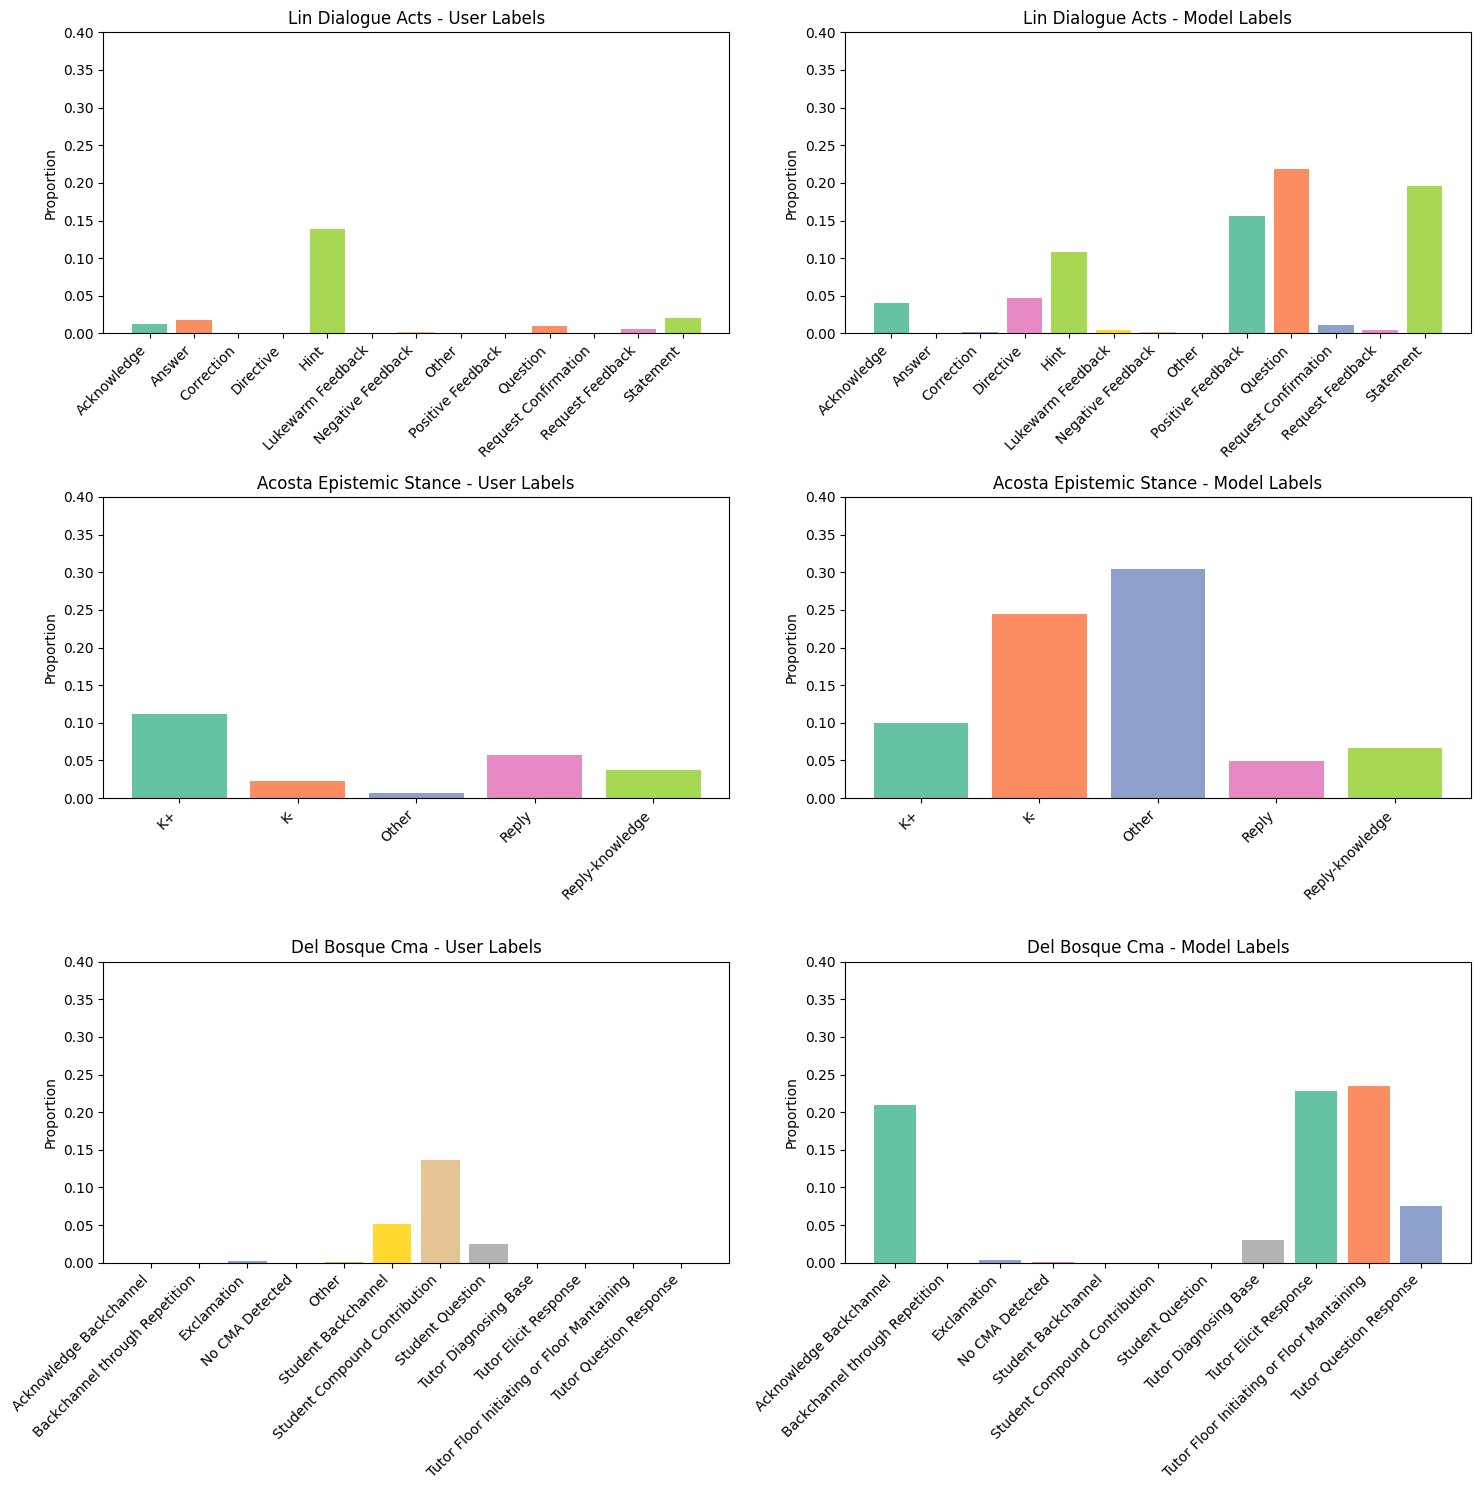

In [12]:
import matplotlib.pyplot as plt

# Set up the figure
fig, axes = plt.subplots(len(data), 2, figsize=(15, 5*len(data)))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

# Different colours for each label type
colors = plt.cm.Set2.colors

# Iterate over each coding scheme
for row_idx, (scheme_name, scheme_data) in enumerate(data.items()):
    ax_user = axes[row_idx, 0]
    ax_model = axes[row_idx, 1]

    # Extract and sort the data for user_labels
    user_labels = sorted(scheme_data['user_labels'].items(), key=lambda x: x[0])
    user_categories, user_values = zip(*user_labels)

    # Extract and sort the data for model_labels
    model_labels = sorted(scheme_data['model_labels'].items(), key=lambda x: x[0])
    model_categories, model_values = zip(*model_labels)

    # Plot user_labels
    ax_user.bar(user_categories, user_values, color=colors)
    ax_user.set_title(f'{scheme_name.replace("_", " ").title()} - User Labels')
    ax_user.set_ylabel('Proportion')
    ax_user.set_ylim(0, 0.4)
    ax_user.set_xticklabels([x[0] for x in user_labels], rotation=45, ha='right')

    # Plot model_labels
    ax_model.bar(model_categories, model_values, color=colors)
    ax_model.set_title(f'{scheme_name.replace("_", " ").title()} - Model Labels')
    ax_model.set_ylabel('Proportion')
    ax_model.set_ylim(0, 0.4)
    ax_model.set_xticklabels([x[0] for x in model_labels], rotation=45, ha='right')

plt.tight_layout()
plt.savefig(path_figures / 'aggregate_label_frequencies.png', dpi=200, bbox_inches='tight')
plt.show()

## N-GRAMS

In [13]:
def get_ngrams_count(df, activity_key, case_id_key, timestamp_key, n=3):

    # Concatenate the activity with the role of the speaker
    df['activity'] = df['role'].str[:1] + '_' + df[activity_key]
    # Transform into an event log
    ccel = pm4py.format_dataframe(df.copy(),
                                case_id=case_id_key,
                                activity_key='activity',
                                timestamp_key=timestamp_key)
    # Get the variants
    cases = []
    variants = pm4py.stats.get_variants(ccel)

    for variant in variants:
        cases += [variant] * variants[variant]

    ngram_counts = {}

    for case in cases:
        for x in range(len(case) - n + 1):
            this_ngram = case[x:x + n]
            ngram_counts[this_ngram] = ngram_counts.get(this_ngram, 0) + 1

    return ngram_counts

def get_top_k_ngrams(df, activity_key, case_id_key, timestamp_key, n=3, k=10):
    ngram_counts = get_ngrams_count(df, activity_key, case_id_key, timestamp_key, n)
    # Sort the dictionary by values in descending order and get the top-k pairs
    top_k_pairs = sorted(ngram_counts.items(), key=lambda item: item[1], reverse=True)[:k]
    return top_k_pairs

In [14]:
rows = []
for code in logs:
    for n in (3, 4):
        top_k = get_top_k_ngrams(logs[code].copy(),
                                 activity_key='ocel:activity',
                                 case_id_key='case_id',
                                 timestamp_key='ocel:timestamp',
                                 n=n)
        for ngram, count in top_k:
            rows.append({'coding_scheme': code, 'n': n, 'ngram': ' -> '.join(ngram), 'count': count})

aggregate_ngrams = pd.DataFrame(rows)
aggregate_ngrams.to_csv(path_tables / 'aggregate_top_ngrams.csv', index=False)
aggregate_ngrams

/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be re

,coding_scheme,n,ngram,count
0,lin_dialogue_acts,3,m_Question -> u_Hint -> m_Positive Feedback,169
1,lin_dialogue_acts,3,u_Hint -> m_Positive Feedback -> m_Question,145
2,lin_dialogue_acts,3,u_Hint -> m_Positive Feedback -> m_Hint,139
3,lin_dialogue_acts,3,m_Positive Feedback -> m_Hint -> m_Question,115
4,lin_dialogue_acts,3,m_Question -> m_Directive -> u_Hint,90
5,lin_dialogue_acts,3,m_Question -> m_Statement -> u_Hint,88
6,lin_dialogue_acts,3,m_Statement -> u_Hint -> m_Positive Feedback,87
7,lin_dialogue_acts,3,m_Directive -> u_Hint -> m_Positive Feedback,82
8,lin_dialogue_acts,3,m_Statement -> m_Question -> m_Directive,77
9,lin_dialogue_acts,3,u_Hint -> m_Positive Feedback -> m_Statement,71


## CLUSTER STATS

### Conversations per cluster

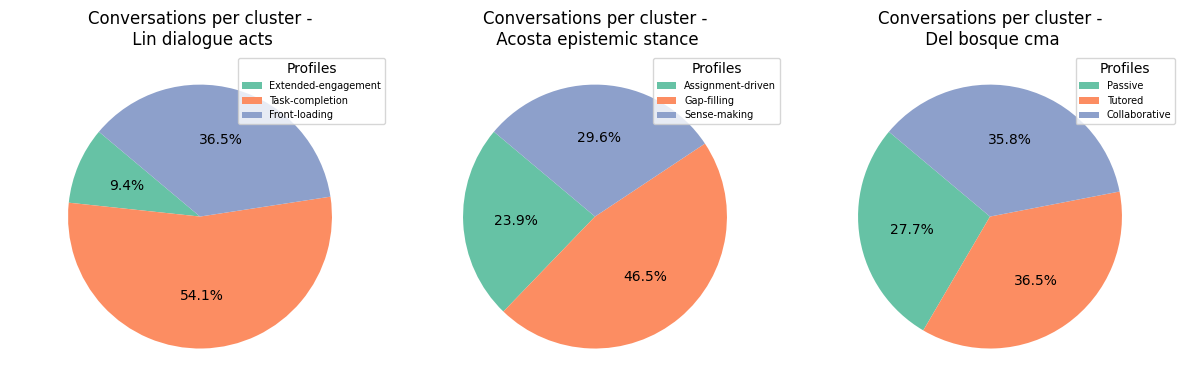

In [15]:
from matplotlib.colors import ListedColormap

# Use a colormap like 'Set3', 'Set2', etc.
cmap = ListedColormap(plt.get_cmap('Set2').colors)

num_rows = len(logs)
fig, axes = plt.subplots(1, num_rows, figsize=(4 * num_rows, 4))

rows = []
for i, coding_scheme in enumerate(logs):

    data_clusters = get_distribution_for_clusters(logs[coding_scheme])
    labels = [PROFILE_NAMES[coding_scheme][c] for c in data_clusters.keys()]

    sizes = list(data_clusters.values())
    # Create the pie chart without labels outside
    wedges, _, _ = axes[i].pie(sizes, startangle=140, autopct='%1.1f%%', colors=cmap(range(len(labels))))

    # Add a legend box
    axes[i].legend(wedges, labels, title="Profiles", loc="upper right", bbox_to_anchor=(1, 1), fontsize=7)

    axes[i].set_title(f"Conversations per cluster -\n {coding_scheme.replace('_',' ').capitalize()}")
    axes[i].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

    for cluster, n in data_clusters.items():
        rows.append({'coding_scheme': coding_scheme, 'cluster': cluster,
                     'profile': PROFILE_NAMES[coding_scheme][cluster], 'n_conversations': n,
                     'pct': round(100 * n / sum(sizes), 1)})

plt.tight_layout()
plt.savefig(path_figures / 'profiles_sizes.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(rows).to_csv(path_tables / 'profiles_sizes.csv', index=False)

### Turns and characters per cluster

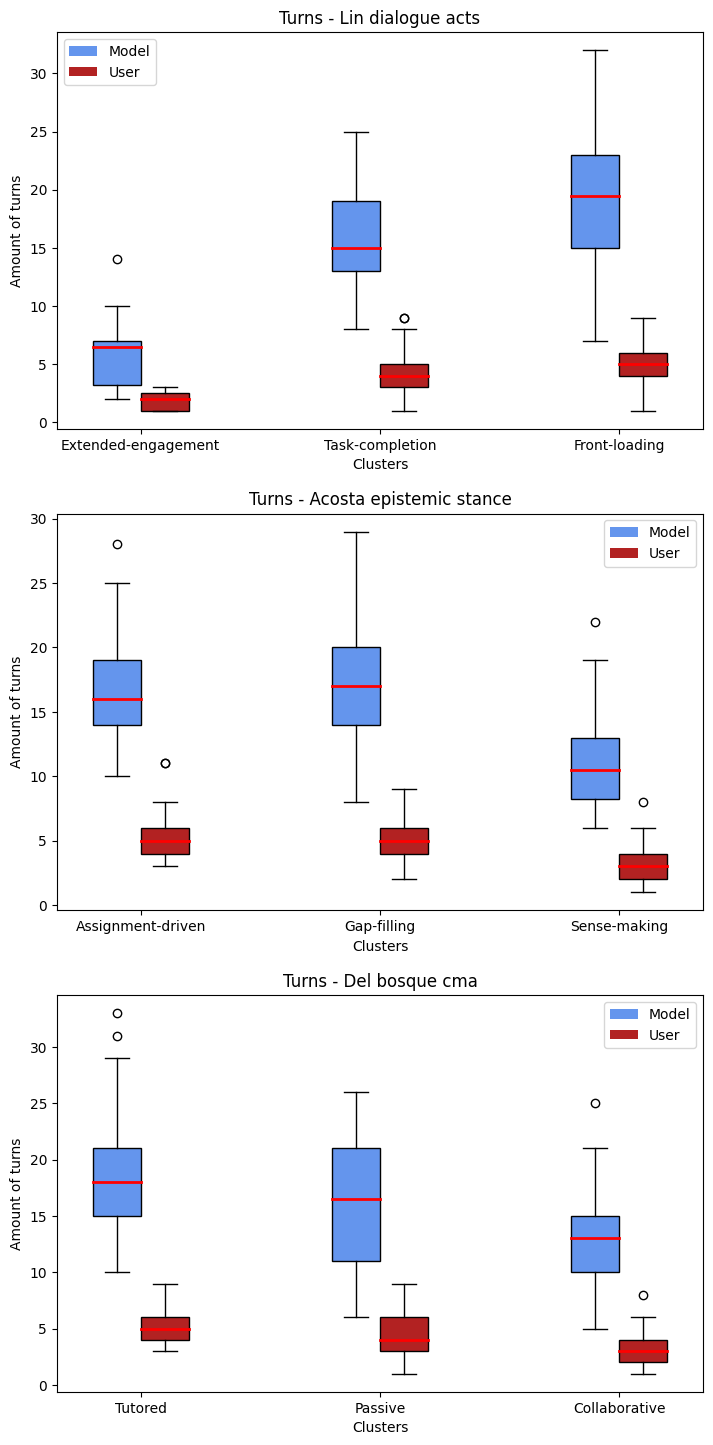

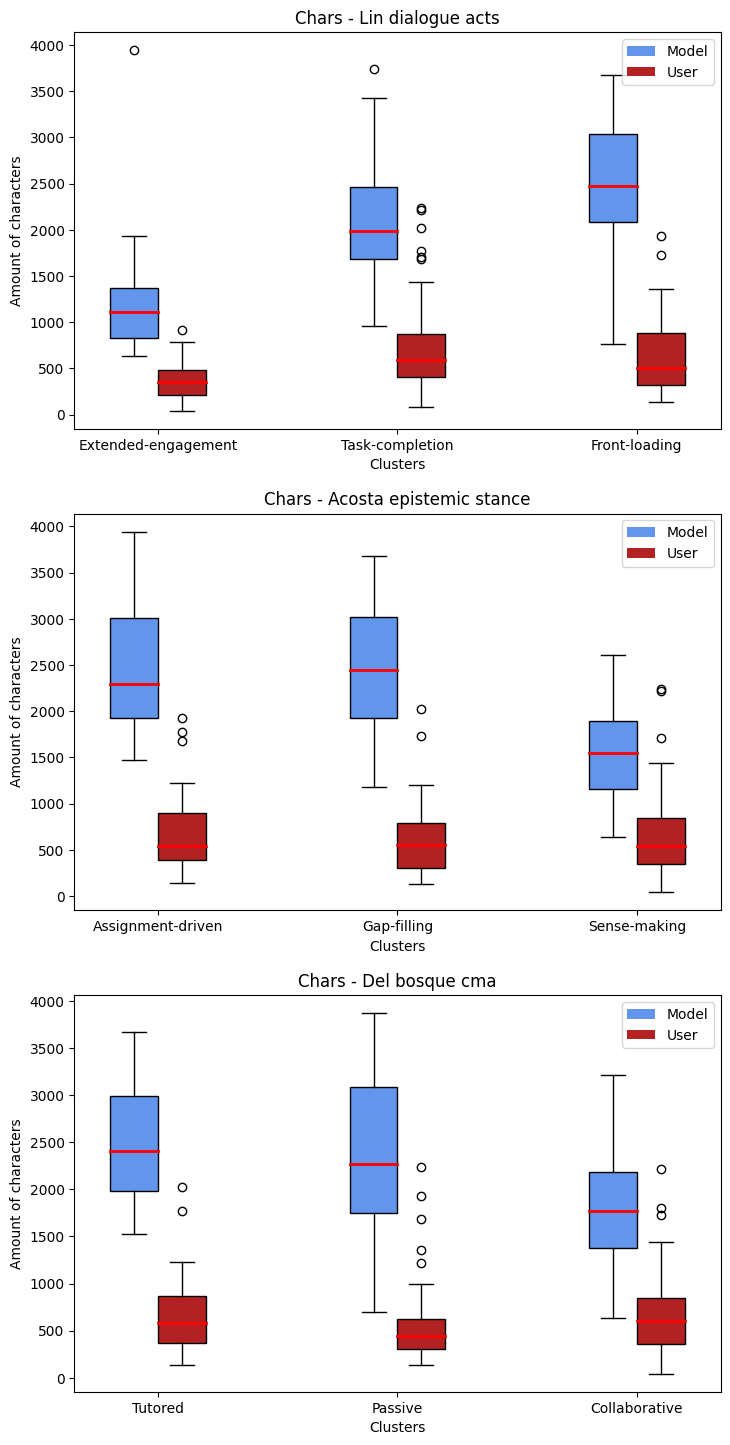

In [16]:
from matplotlib.patches import Patch  # For legend creation

for measure, function, ylabel in [('Turns', count_turns, 'Amount of turns'),
                                  ('Chars', sum_sentence_length, 'Amount of characters')]:

    num_dataframes = len(logs)
    fig, axes = plt.subplots(nrows=num_dataframes, ncols=1, figsize=(8, 5 * num_dataframes))

    # Ensure axes is always treated as an array
    axes = np.atleast_1d(axes)

    # Adjust spacing between subplots
    fig.tight_layout(pad=4.0)

    # Iterate over each DataFrame in the list
    for j, coding_scheme in enumerate(logs):
        total_count = function(logs[coding_scheme])

        data_measure = []
        for k in total_count:
            pair = []
            for v in total_count[k]:
                pair.append(total_count[k][v])
            data_measure.append(pair)

        # Define positions for the boxes
        positions = np.arange(len(data_measure)) * 2  # Cluster positions (0, 2, 4)
        width = 0.4  # Width of each box

        # Colors for agents
        colors = {"Model": "cornflowerblue", "User": "firebrick"}

        ax = axes[j]  # Select the current subplot

        # Plot boxes for each cluster
        for i, (agent1_data, agent2_data) in enumerate(data_measure):

            median_props = dict(color='red', linewidth=2)

            # Agent 1 box
            ax.boxplot(agent1_data, positions=[positions[i] - width / 2], widths=width,
                       patch_artist=True, boxprops=dict(facecolor=colors["Model"]),
                       medianprops=median_props)

            # Agent 2 box
            ax.boxplot(agent2_data, positions=[positions[i] + width / 2], widths=width,
                       patch_artist=True, boxprops=dict(facecolor=colors["User"]),
                       medianprops=median_props)

        # Create proxy artists for the legend
        proxy_artist1 = Patch(facecolor=colors["Model"], label="Model")
        proxy_artist2 = Patch(facecolor=colors["User"], label="User")

        # Add legend
        ax.legend([proxy_artist1, proxy_artist2], ["Model", "User"])

        # Customize the plot
        ax.set_xticks(positions)
        ax.set_xticklabels([PROFILE_NAMES[coding_scheme][c] for c in sorted(total_count.keys())])
        ax.set_xlabel("Clusters")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{measure} - {coding_scheme.replace('_',' ').capitalize()}")

    plt.savefig(path_figures / f'profiles_{measure.lower()}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [17]:
rows = []
for code in logs:
    df = logs[code]

    turns = count_turns(df)
    chars = sum_sentence_length(df)

    for cluster in sorted(turns.keys()):
        temp = df[df['cluster'] == cluster]
        percentage = round(len(temp['case_id'].unique())/len(df['case_id'].unique()) * 100, 1)
        for role in turns[cluster]:
            print(code, cluster, percentage, role,
                  'turns', round(np.mean(turns[cluster][role]), 2),
                  '| chars', round(np.mean(chars[cluster][role]), 2))
            rows.append({'coding_scheme': code, 'cluster': cluster,
                         'profile': PROFILE_NAMES[code][cluster], 'pct_of_conversations': percentage,
                         'role': role,
                         'turns_mean': np.mean(turns[cluster][role]),
                         'turns_median': np.median(turns[cluster][role]),
                         'chars_mean': np.mean(chars[cluster][role]),
                         'chars_median': np.median(chars[cluster][role])})

pd.DataFrame(rows).round(3).to_csv(path_tables / 'profiles_interaction_properties.csv', index=False)

lin_dialogue_acts 0 9.4 model turns 6.21 | chars 1299.93
lin_dialogue_acts 0 9.4 user turns 1.93 | chars 369.4
lin_dialogue_acts 1 54.1 model turns 16.09 | chars 2124.95
lin_dialogue_acts 1 54.1 user turns 4.13 | chars 689.13
lin_dialogue_acts 2 36.5 model turns 19.28 | chars 2506.71
lin_dialogue_acts 2 36.5 user turns 5.16 | chars 620.67
acosta_epistemic_stance 0 23.9 model turns 16.5 | chars 2432.68
acosta_epistemic_stance 0 23.9 user turns 5.63 | chars 680.03
acosta_epistemic_stance 1 46.5 model turns 17.28 | chars 2478.93
acosta_epistemic_stance 1 46.5 user turns 5.08 | chars 592.86
acosta_epistemic_stance 2 29.6 model turns 10.83 | chars 1537.09
acosta_epistemic_stance 2 29.6 user turns 3.23 | chars 660.51
del_bosque_cma 0 36.5 model turns 18.48 | chars 2463.84
del_bosque_cma 0 36.5 user turns 5.19 | chars 652.59
del_bosque_cma 1 27.7 model turns 15.89 | chars 2354.3
del_bosque_cma 1 27.7 user turns 4.39 | chars 593.66
del_bosque_cma 2 35.8 model turns 12.66 | chars 1788.55
del_bo

### Sequence indicators per cluster

In [18]:
rows = []
for code in logs:
    df = logs[code]
    for cluster in sorted(df['cluster'].unique()):

        temp = df[df['cluster'] == cluster].copy()
        percentage = round(len(temp['case_id'].unique())/len(df['case_id'].unique()) * 100, 1)
        res = get_seq_stats(
            temp, activity_key='ocel:activity', case_id_key='case_id',
            timestamp_key='ocel:timestamp', round=True
        )
        print(code, cluster, percentage, res)
        rows.append({'coding_scheme': code, 'cluster': cluster,
                     'profile': PROFILE_NAMES[code][cluster],
                     'pct_of_conversations': percentage, **res})

pd.DataFrame(rows).to_csv(path_tables / 'profiles_sequence_indicators.csv', index=False)

lin_dialogue_acts 0 9.4 {'mean_n_states': 4.133, 'median_n_states': 4.0, 'mean_n_spells': 6.733, 'median_n_spells': 7.0, 'mean_complexity': 0.845, 'median_complexity': 0.815, 'mean_entropy': 0.95, 'median_entropy': 0.946}
lin_dialogue_acts 1 54.1 {'mean_n_states': 6.709, 'median_n_states': 7.0, 'mean_n_spells': 19.221, 'median_n_spells': 18.0, 'mean_complexity': 0.705, 'median_complexity': 0.698, 'mean_entropy': 0.936, 'median_entropy': 0.933}
lin_dialogue_acts 2 36.5 {'mean_n_states': 9.207, 'median_n_states': 9.0, 'mean_n_spells': 23.431, 'median_n_spells': 24.0, 'mean_complexity': 0.642, 'median_complexity': 0.642, 'mean_entropy': 0.909, 'median_entropy': 0.906}
acosta_epistemic_stance 0 23.9 {'mean_n_states': 7.632, 'median_n_states': 8.0, 'mean_n_spells': 21.132, 'median_n_spells': 20.0, 'mean_complexity': 0.666, 'median_complexity': 0.668, 'mean_entropy': 0.898, 'median_entropy': 0.901}
acosta_epistemic_stance 1 46.5 {'mean_n_states': 6.473, 'median_n_states': 6.0, 'mean_n_spells

/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/1541790175.py:63: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will b

### Label distribution per cluster

In [19]:
data = {}
normalize = True
rows = []
for code in logs:
    df = logs[code]
    out = {}
    for cluster in sorted(df['cluster'].unique()):
        temp = df[df['cluster']==cluster]
        result = get_frequency_of_activities(temp, coding_schemes[code],
                                           activity_key='ocel:activity',
                                           case_id_key='case_id',
                                           timestamp_key='ocel:timestamp',
                                           normalize=normalize
                                           )
        out[cluster] = result

        for role in result:
            for label, value in result[role].items():
                rows.append({'coding_scheme': code, 'cluster': cluster,
                             'profile': PROFILE_NAMES[code][cluster],
                             'role': role.replace('_labels', ''), 'activity': label,
                             'frequency': value})
    data[code] = out

pd.DataFrame(rows).to_csv(path_tables / 'profiles_activity_distribution.csv', index=False)

/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/375787844.py:28: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be re

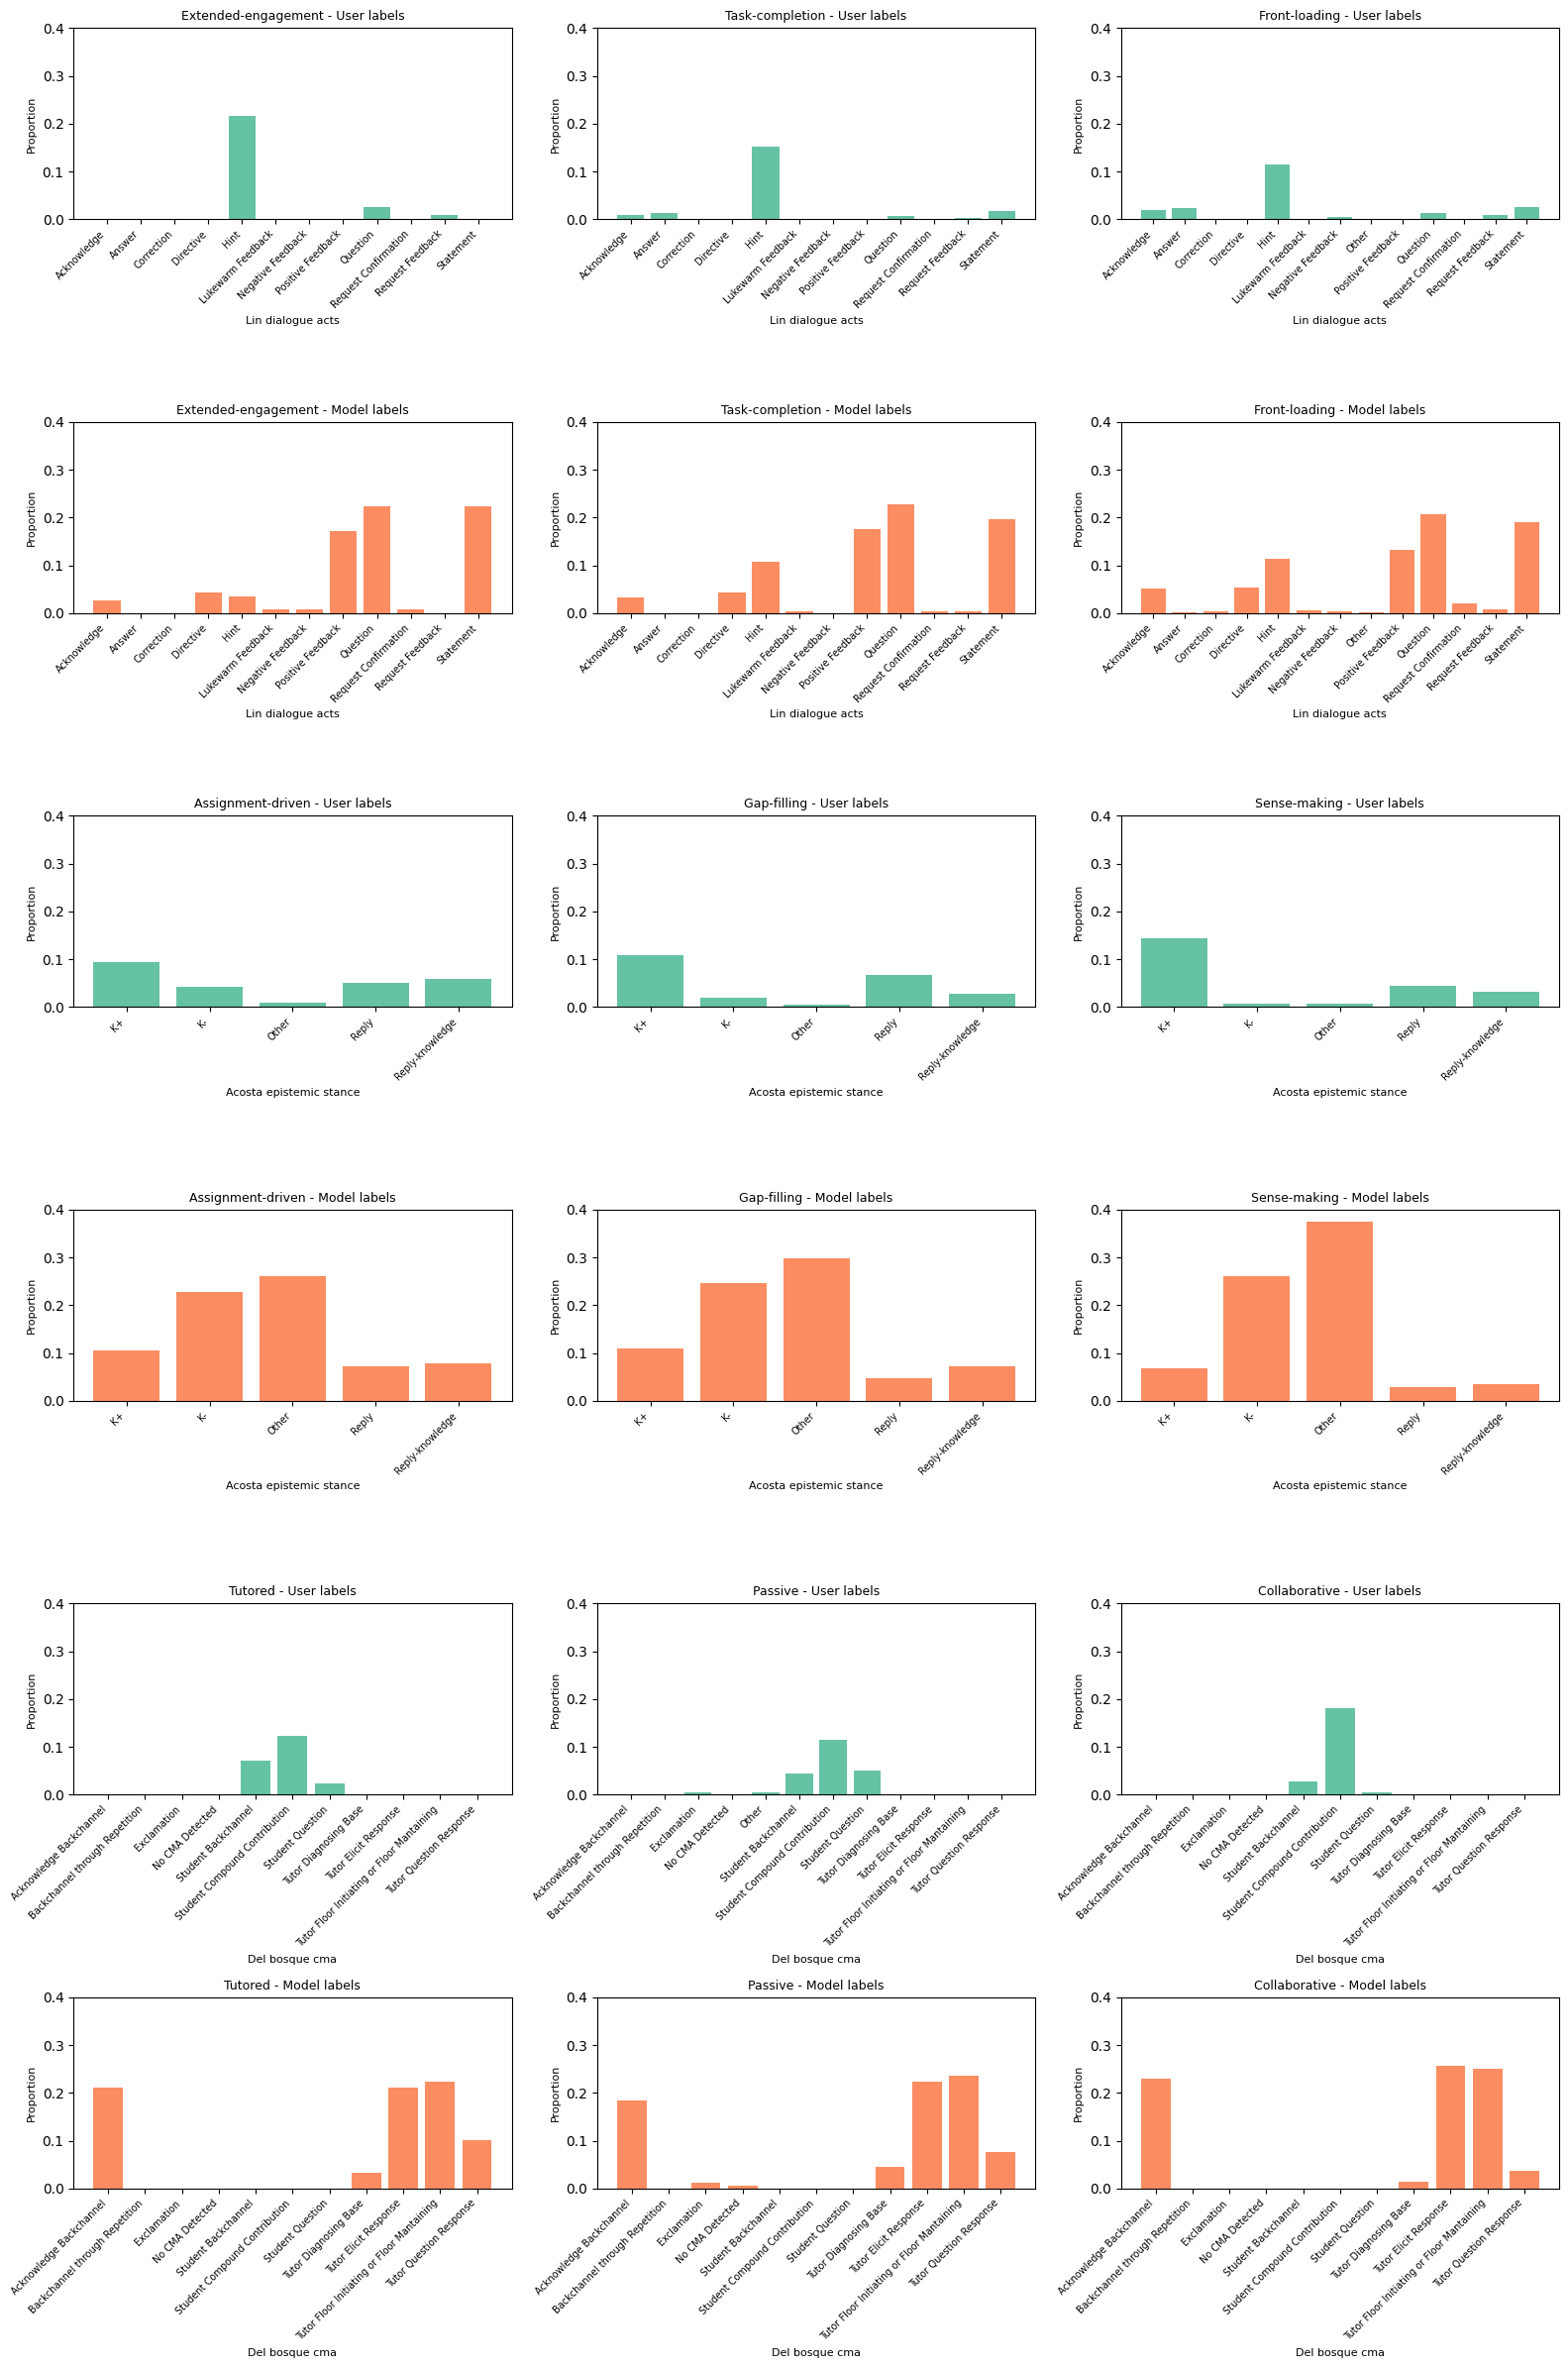

In [20]:
# Create a figure with 2 rows (user_labels and model_labels) and 3 columns (clusters)
fig, axes = plt.subplots(2 * len(data), 3, figsize=(16, 8 * len(data)))

# Flatten the axes for easier iteration
axes = axes.flatten()

for k, coding_scheme in enumerate(data):

    aux = data[coding_scheme]
    # Define the clusters and labels
    clusters_list = sorted(list(aux.keys()))
    label_types = ['user_labels', 'model_labels']  # Row 1: user_labels, Row 2: model_labels
    colors = cmap(range(len(label_types)))
    # Iterate over clusters and label types to populate the subplots
    for i, cluster in enumerate(clusters_list):
        for j, label_type in enumerate(label_types):
            # Calculate the subplot index
            ax_index = i + j * len(clusters_list) + k * 6  # Column-major order

            # Get the data for the current cluster and label type
            labels = list(aux[cluster][label_type].keys())
            values = list(aux[cluster][label_type].values())

            # Sort labels alphabetically and reorder values accordingly
            sorted_indices = sorted(range(len(labels)), key=lambda k: labels[k])
            labels = [labels[idx] for idx in sorted_indices]
            values = [values[idx] for idx in sorted_indices]

            # Plot the bar chart
            axes[ax_index].bar(labels, values, color=colors[0] if label_type == 'user_labels' else colors[1])
            axes[ax_index].set_title(f'{PROFILE_NAMES[coding_scheme][cluster]} - {label_type.replace("_", " ").capitalize()}',
                                     fontsize=9)
            axes[ax_index].set_xlabel(f'{coding_scheme.replace("_", " ").capitalize()}', fontsize=8)
            axes[ax_index].set_ylabel('Proportion', fontsize=8)

            axes[ax_index].set_ylim(0, 0.4)

            # Tilt x-axis labels for better readability
            axes[ax_index].set_xticks(range(len(labels)))
            axes[ax_index].set_xticklabels(labels, rotation=45, ha='right', fontsize=7)

plt.tight_layout()
plt.savefig(path_figures / 'profiles_label_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

### Most frequent n-grams per cluster

In [21]:
rows = []
for code in logs:
    df = logs[code]
    for cluster in sorted(df['cluster'].unique()):
        temp = df[df['cluster'] == cluster]
        for n in (3, 4):
            top_k = get_top_k_ngrams(temp.copy(),
                                     activity_key='ocel:activity',
                                     case_id_key='case_id',
                                     timestamp_key='ocel:timestamp',
                                     n=n)
            for ngram, count in top_k:
                rows.append({'coding_scheme': code, 'cluster': cluster,
                             'profile': PROFILE_NAMES[code][cluster], 'n': n,
                             'ngram': ' -> '.join(ngram), 'count': count})

profile_ngrams = pd.DataFrame(rows)
profile_ngrams.to_csv(path_tables / 'profiles_top_ngrams.csv', index=False)
profile_ngrams[profile_ngrams['n'] == 3]

/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be re

,coding_scheme,cluster,profile,n,ngram,count
0,lin_dialogue_acts,0,Extended-engagement,3,u_Hint -> m_Positive Feedback -> m_Question,12
1,lin_dialogue_acts,0,Extended-engagement,3,m_Question -> u_Hint -> m_Positive Feedback,8
2,lin_dialogue_acts,0,Extended-engagement,3,m_Statement -> u_Hint -> m_Positive Feedback,7
3,lin_dialogue_acts,0,Extended-engagement,3,m_Positive Feedback -> m_Question -> u_Hint,6
4,lin_dialogue_acts,0,Extended-engagement,3,m_Statement -> m_Question -> m_Statement,5
...,...,...,...,...,...,...
165,del_bosque_cma,2,Collaborative,3,u_Student Compound Contribution -> m_Acknowled...,49
166,del_bosque_cma,2,Collaborative,3,m_Acknowledge Backchannel -> m_Tutor Floor Ini...,44
167,del_bosque_cma,2,Collaborative,3,m_Acknowledge Backchannel -> m_Tutor Elicit Re...,38
168,del_bosque_cma,2,Collaborative,3,m_Tutor Floor Initiating or Floor Mantaining -...,28


/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be removed in 3.0.0. the format_dataframe function does not need application anymore.
  ccel = pm4py.format_dataframe(df.copy(),
/var/folders/2p/6lphg4ds5rl5qqm90rxg3v0r0000gn/T/ipykernel_3823/3543269948.py:6: DeprecatedWarning: format_dataframe is deprecated as of 2.3.0 and will be re

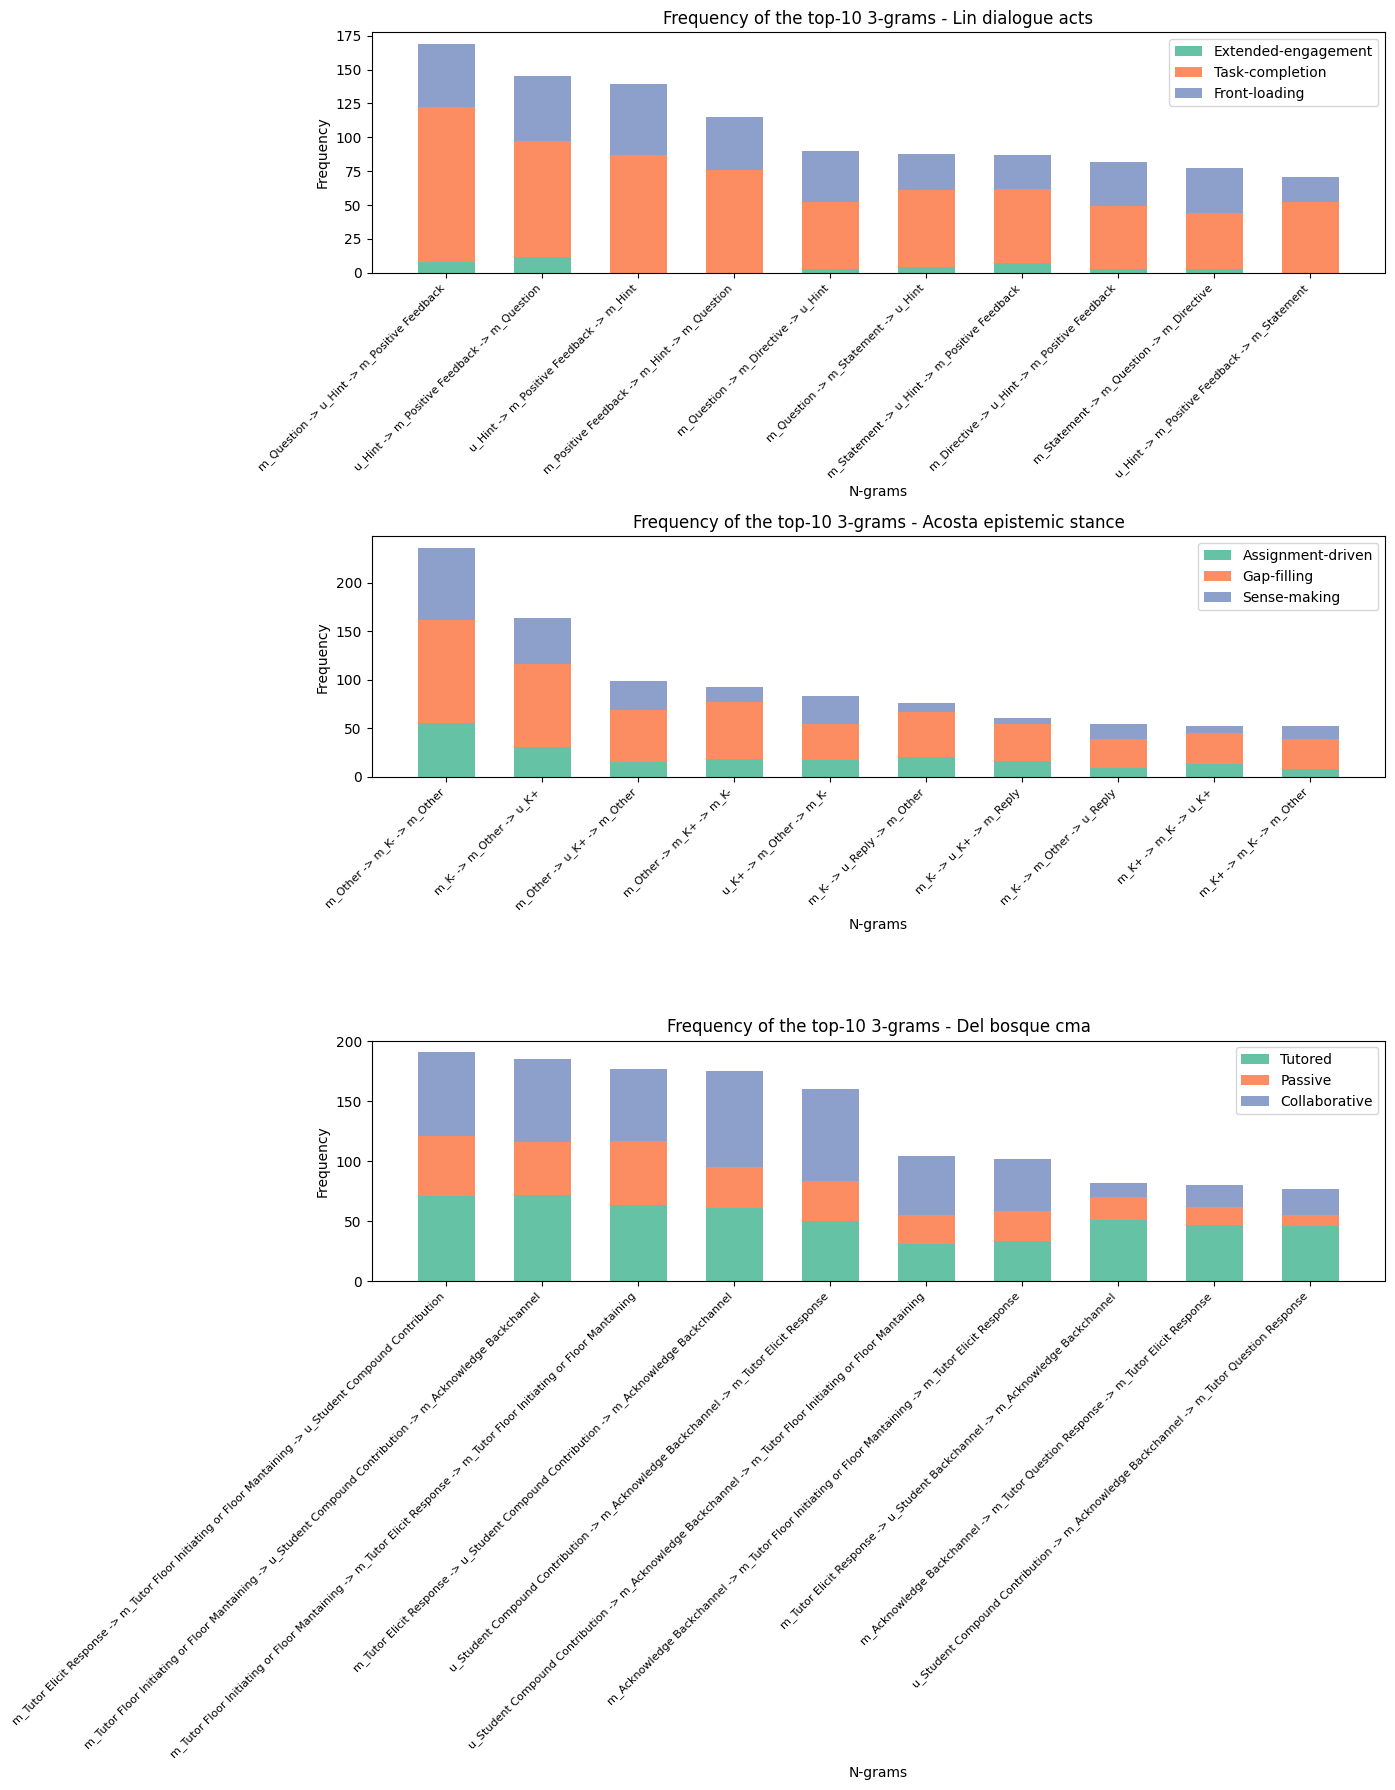

In [22]:
# Frequency of the top-10 3-grams of the whole log, split by cluster
fig, axes = plt.subplots(nrows=len(logs), ncols=1, figsize=(14, 6 * len(logs)))
axes = np.atleast_1d(axes)

for i, code in enumerate(logs):

    df = logs[code]

    ngrams_universe = get_ngrams_count(df.copy(),
                            activity_key='ocel:activity',
                            case_id_key='case_id',
                            timestamp_key='ocel:timestamp', n=3)

    clusters_ngrams = []
    for cluster in sorted(df['cluster'].unique()):
        temp = df[df['cluster'] == cluster]
        ngrams_cluster = get_ngrams_count(temp.copy(),
                            activity_key='ocel:activity',
                            case_id_key='case_id',
                            timestamp_key='ocel:timestamp', n=3)
        clusters_ngrams.append(ngrams_cluster)

    colors = cmap(range(len(clusters_ngrams)))

    # Select the top-10 n-grams by frequency in the whole log
    top_ngrams = sorted(ngrams_universe, key=ngrams_universe.get, reverse=True)[:10]

    plot_df = pd.DataFrame({
        'n-gram': [' -> '.join(ngram) for ngram in top_ngrams],
        'Cluster 0': [clusters_ngrams[0].get(ngram, 0) for ngram in top_ngrams],
        'Cluster 1': [clusters_ngrams[1].get(ngram, 0) for ngram in top_ngrams],
        'Cluster 2': [clusters_ngrams[2].get(ngram, 0) for ngram in top_ngrams],
    })

    ax = axes[i]
    bar_width = 0.6
    x = range(len(plot_df['n-gram']))
    ax.bar(x, plot_df['Cluster 0'], label=PROFILE_NAMES[code][0], color=colors[0], width=bar_width)
    ax.bar(x, plot_df['Cluster 1'], bottom=plot_df['Cluster 0'], label=PROFILE_NAMES[code][1],
           color=colors[1], width=bar_width)
    ax.bar(x, plot_df['Cluster 2'], bottom=plot_df['Cluster 0'] + plot_df['Cluster 1'],
           label=PROFILE_NAMES[code][2], color=colors[2], width=bar_width)

    ax.set_xlabel('N-grams')
    ax.set_ylabel('Frequency')
    ax.set_title(f'Frequency of the top-10 3-grams - {code.replace("_", " ").capitalize()}')
    ax.legend()
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df['n-gram'], rotation=45, ha='right', fontsize=8)

plt.tight_layout()
plt.savefig(path_figures / 'profiles_top_ngrams.png', dpi=200, bbox_inches='tight')
plt.show()